# 채널 LES 검증 — Re_τ ≈ 365 (Vreman 2004 Phys. Fluids 16 §V.B 조건)

LES 검증 논문(Vreman 2004, `docs/Paper/Constant_vreman.pdf`)의 채널 시험이 Re_τ ≈ 360~364 라서 **이 기준만** 본다 (2026-10-20 사용자 지시).
Re_τ 180 LES 비교(64³·96³, CPU vs GPU)는 이 노트북에서 뺐다 — git 커밋 4e1c60a 이전 판, 데이터는 `stats_les64_*`, `stats_les96_*`.

- 조건: 상자 6H × 2H × 2H, 격자 47 × 47 × 63 (Δx⁺ ≈ 50, Δy⁺ ≈ 17), 2차 FD, Re_b 6198. 논문은 **압력구배 고정**(DNS Re_τ 364, Hu & Sandham),
  우리 런은 **유량 고정**이라 Re_τ 가 결과값.
- 참조: Re_τ·C_f 는 논문 Table II (DNS Re_τ 364, C_f(bulk) 0.00667; 모델 361 / −1.5%, dynamic 359 / −4.6%, 0-model 363 / +8.5%).
  프로파일은 MKM Re_τ 395(392.2) — 논문 본문이 360 DNS 와 평균·강도가 겹친다고 명시한 대체(원 데이터 서버 소멸).
- rms·−u′w′ 는 **해상 성분만**(논문 fig.5(a)·(c) 'resolved' 대응; 아격자 기여 미포함).
- 케이스: 모델 없음·Vreman C_s 0.12 (mirror 벽, 표준), Vreman 0.17 (value 벽, 참고). 실선 = mirror, 파선 = value 벽.

구성 — §1 요약 표 · §2 Re_τ 이력·평균 속도 · §3 rms·전단·와점성.

In [1]:
import glob, os, re
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

APP = os.path.abspath(os.path.join(os.getcwd(), ".."))
HERE = os.getcwd()
NU = 1.0 / 2857.0

MODEL_COLOR = {"none": "#8a8984", "vreman": "#2a78d6", "wale": "#1baf7a", "vreman017": "#eda100", "value": "#e87ba4"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2.0, "legend.frameon": False, "legend.fontsize": 8,
})

In [2]:
def read_stats(path):
    meta = {}
    for line in open(path):
        if line.startswith("#"):
            for k, v in re.findall(r"(\w+)=([-0-9.eE+]+)", line): meta[k] = float(v)
    d = np.loadtxt(path, comments="#")
    nz = len(d); k = np.arange(nz // 2)
    sym = lambda a, sign=1: 0.5 * (a[k] + sign * a[nz - 1 - k])     # 아래·위 반쪽 평균 (uw 는 반대칭)
    ut = meta["u_tau"]
    return meta, dict(zp=sym(d[:, 1]), Up=sym(d[:, 3]), urms=sym(d[:, 4]) / ut, vrms=sym(d[:, 5]) / ut,
                      wrms=sym(d[:, 6]) / ut, uw=-sym(d[:, 7], -1) / ut**2, nut=sym(d[:, 8]) if d.shape[1] > 8 else 0 * k)

def read_monitor(path):
    rows = []
    for line in open(path):
        parts = line.split()
        if len(parts) == 9 and re.match(r"^\s+\d+\s", line):
            rows.append([float(x) for x in parts])
    d = np.array(rows)
    return dict(step=d[:, 0], time=d[:, 1], re_tau=d[:, 6])



## 1. 요약 표 — Re_τ 는 목표 364 대비, 프로파일 오차는 MKM 395 정점 대비

In [3]:
RE365_TARGET = 364.0
CASES_365 = [
    dict(key="re360_les_none_mirror",      model="none",      ls="-",  label="Re365 no model (mirror)"),
    dict(key="re360_les_vreman012_mirror", model="vreman",    ls="-",  label="Re365 Vreman 0.12 (mirror)"),
    dict(key="re360_les_vreman017",        model="vreman017", ls="--", label="Re365 Vreman 0.17 (value wall)"),
]
LOG_365 = {"re360_les_none_mirror": "les360_none_mirror.log", "re360_les_vreman012_mirror": "les360_vreman012_mirror.log",
           "re360_les_vreman017": "les360_vreman017.log"}
runs365 = []
for c in CASES_365:
    paths = sorted(glob.glob(f"{APP}/stats_{c['key']}/channel_stats_*.dat"))
    if not paths: print(f"[{c['label']}] 통계 없음"); continue
    meta, prof = read_stats(paths[-1]); log = f"{APP}/log/{LOG_365[c['key']]}"
    runs365.append(dict(c, meta=meta, prof=prof, monitor=read_monitor(log) if os.path.exists(log) else None))
mean395 = np.loadtxt(f"{HERE}/ref_mean_395.txt", comments="%"); fluc395 = np.loadtxt(f"{HERE}/ref_fluc_395.txt", comments="%")
mkm395 = dict(zp=mean395[:, 1], Up=mean395[:, 2], urms=np.sqrt(fluc395[:, 2]), wrms=np.sqrt(fluc395[:, 3]),  # MKM v = 벽수직 → 우리 w
              vrms=np.sqrt(fluc395[:, 4]), uw=-fluc395[:, 5])                                                 # MKM w = 스팬 → 우리 v
RE_395 = float(mean395[-1, 1] / mean395[-1, 0])

# 요약 표 — Re_τ 는 목표 364 대비, 프로파일은 MKM 395 대비
print(f"{'case':<32} {'Re_tau':>7} {'vs 364':>7} {'Cf_bulk':>8} {'U+ logRMS':>9} {'urms':>6} {'vrms':>6} {'wrms':>6} {'-uw':>6}")
for r in runs365:
    p = r["prof"]; re_tau = r["meta"]["Re_tau"]; ut = r["meta"]["u_tau"]
    mask = (p["zp"] > 30) & (p["zp"] < 0.3 * re_tau)
    log_rms = float(np.sqrt(np.mean((p["Up"][mask] - np.interp(p["zp"][mask], mkm395["zp"], mkm395["Up"])) ** 2)))
    pk = {k: 100 * (p[k].max() / mkm395[k].max() - 1) for k in ("urms", "vrms", "wrms", "uw")}
    r["m365"] = dict(re=re_tau, log_rms=log_rms, peak=pk)
    print(f"{r['label']:<32} {re_tau:7.1f} {100*(re_tau/RE365_TARGET-1):+6.1f}% {2*ut**2:8.5f} {log_rms:9.2f} "
          f"{pk['urms']:+5.0f}% {pk['vrms']:+5.0f}% {pk['wrms']:+5.0f}% {pk['uw']:+5.0f}%")
print(f"references: target Re_tau {RE365_TARGET:.0f} (Vreman Table II DNS, Cf_bulk 0.00667); profiles MKM Re_tau {RE_395:.1f}")
print("Vreman 2004 Table II: present model Re_tau 361 (Cf -1.5%), dynamic 359 (-4.6%), 0-model 363 (+8.5%)")



case                              Re_tau  vs 364  Cf_bulk U+ logRMS   urms   vrms   wrms    -uw
Re365 no model (mirror)            392.7   +7.9%  0.00803      1.27    +9%    -9%    -4%   -12%
Re365 Vreman 0.12 (mirror)         372.9   +2.5%  0.00724      0.25    +7%   -10%    -7%   -14%
Re365 Vreman 0.17 (value wall)     351.9   -3.3%  0.00645      0.88    +8%   -12%   -10%   -14%
references: target Re_tau 364 (Vreman Table II DNS, Cf_bulk 0.00667); profiles MKM Re_tau 392.2
Vreman 2004 Table II: present model Re_tau 361 (Cf -1.5%), dynamic 359 (-4.6%), 0-model 363 (+8.5%)


## 2. Re_τ 이력과 평균 속도 U⁺

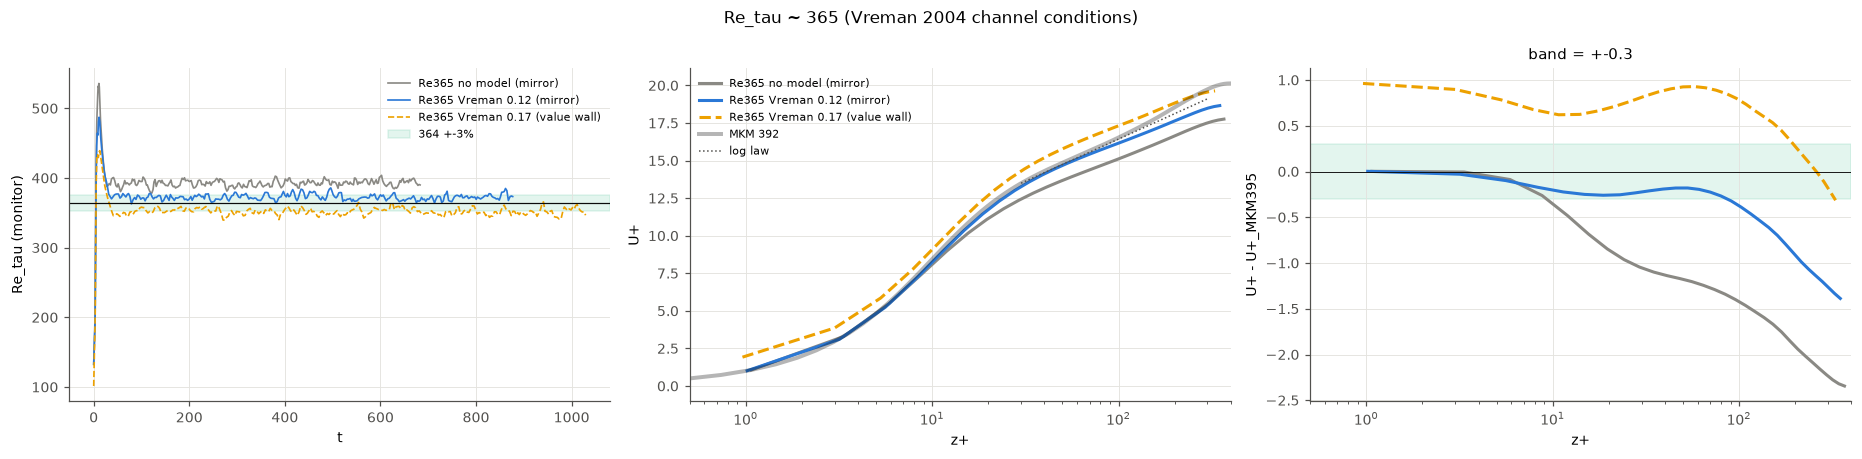

In [4]:
# 그림 1: Re_τ 이력 + U⁺ + U⁺ 차이
figure, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for r in runs365:
    st = dict(color=MODEL_COLOR[r["model"]], ls=r["ls"])
    if r["monitor"] is not None: axes[0].plot(r["monitor"]["time"], r["monitor"]["re_tau"], lw=1.1, label=r["label"], **st)
    axes[1].semilogx(r["prof"]["zp"], r["prof"]["Up"], label=r["label"], **st)
    axes[2].semilogx(r["prof"]["zp"], r["prof"]["Up"] - np.interp(r["prof"]["zp"], mkm395["zp"], mkm395["Up"]), **st)
axes[0].axhspan(RE365_TARGET * 0.97, RE365_TARGET * 1.03, color="#1baf7a", alpha=0.12, label="364 +-3%")
axes[0].axhline(RE365_TARGET, color=INK, lw=0.8); axes[0].set_xlabel("t"); axes[0].set_ylabel("Re_tau (monitor)"); axes[0].legend(fontsize=7)
axes[1].semilogx(mkm395["zp"], mkm395["Up"], color=INK, lw=2.6, alpha=0.3, label=f"MKM {RE_395:.0f}")
zl = np.linspace(30, 300, 30); axes[1].semilogx(zl, np.log(zl) / 0.41 + 5.2, color=MUTED, lw=1, ls=":", label="log law")
axes[1].set_xlim(0.5, 400); axes[1].set_xlabel("z+"); axes[1].set_ylabel("U+"); axes[1].legend(fontsize=7)
axes[2].axhspan(-0.3, 0.3, color="#1baf7a", alpha=0.12); axes[2].axhline(0, color=INK, lw=0.6)
axes[2].set_xlim(0.5, 400); axes[2].set_xlabel("z+"); axes[2].set_ylabel("U+ - U+_MKM395"); axes[2].set_title("band = +-0.3")
figure.suptitle("Re_tau ~ 365 (Vreman 2004 channel conditions)"); figure.tight_layout(); plt.show()



## 3. 해상 rms·레이놀즈 전단과 와점성

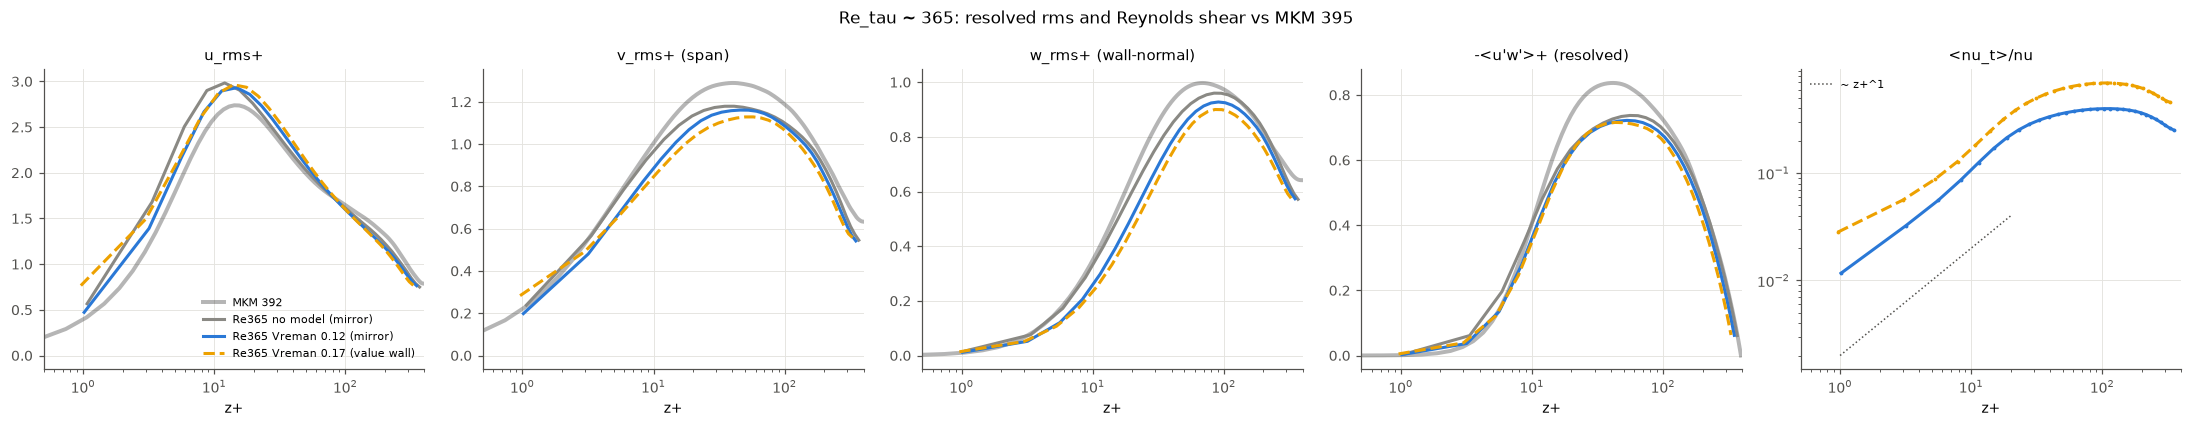

In [5]:
# 그림 2: rms·전단·와점성
panels = [("urms", "u_rms+"), ("vrms", "v_rms+ (span)"), ("wrms", "w_rms+ (wall-normal)"), ("uw", "-<u'w'>+ (resolved)")]
figure, axes = plt.subplots(1, 5, figsize=(20, 3.9))
for ax, (key, title) in zip(axes, panels):
    ax.plot(mkm395["zp"], mkm395[key], color=INK, lw=2.6, alpha=0.3, label=f"MKM {RE_395:.0f}")
    for r in runs365: ax.plot(r["prof"]["zp"], r["prof"][key], color=MODEL_COLOR[r["model"]], ls=r["ls"], label=r["label"])
    ax.set_xscale("log"); ax.set_xlim(0.5, 400); ax.set_xlabel("z+"); ax.set_title(title)
axes[0].legend(fontsize=7)
ax = axes[4]
for r in runs365:
    p = r["prof"]; good = p["nut"] > 1e-12
    if good.any(): ax.loglog(p["zp"][good], p["nut"][good], color=MODEL_COLOR[r["model"]], ls=r["ls"], marker=".", ms=3)
zl = np.logspace(0, 1.3, 10); ax.loglog(zl, 2e-3 * zl, color=MUTED, lw=1, ls=":", label="~ z+^1")
ax.set_xlim(0.5, 400); ax.set_xlabel("z+"); ax.set_title("<nu_t>/nu"); ax.legend(fontsize=7)
figure.suptitle("Re_tau ~ 365: resolved rms and Reynolds shear vs MKM 395"); figure.tight_layout(); plt.show()
